# Tesla, BYD, and NIO: Stock Comparison

## Research Question

How did Tesla, BYD, and NIO differ in stock performance,
daily return volatility, and return correlations?

## Data

- Tickers: TSLA, BYDDY, NIO
- Requested period: January 1–October 11, 2026
- Exclusive download end date: October 12, 2026
- Source: Yahoo Finance through yfinance.download()
- Prices: Adjusted closing prices in USD

We compare normalized prices rather than raw share prices
because the securities have different starting price levels.

In [11]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
tickers = ["TSLA", "BYDDY", "NIO"]
data = yf.download(
    tickers,
    start="2026-01-01",
    end="2026-10-12",
    auto_adjust=True,
    progress=False
)
prices = data["Close"].reindex(columns=tickers).sort_index()
if prices.empty or prices.isna().all().any():
    raise ValueError("Some stock data was not downloaded successfully.")

print("First date:", prices.index.min().date())
print("Last date:", prices.index.max().date())
print("\nPrice observations:")
print(prices.count())
print("\nMissing prices:")
print(prices.isna().sum())
print("\nDuplicate dates:", prices.index.duplicated().sum())

prices.head()

First date: 2026-01-02
Last date: 2026-10-09

Price observations:
Ticker
TSLA     194
BYDDY    194
NIO      194
dtype: int64

Missing prices:
Ticker
TSLA     0
BYDDY    0
NIO      0
dtype: int64

Duplicate dates: 0


Ticker,TSLA,BYDDY,NIO
Date,,,
2026-01-02,438.070007,12.698576,5.14
2026-01-05,451.670013,12.409972,4.86
2026-01-06,432.959991,12.549297,4.78
2026-01-07,431.410004,12.041754,4.79
2026-01-08,435.799988,12.131319,4.73


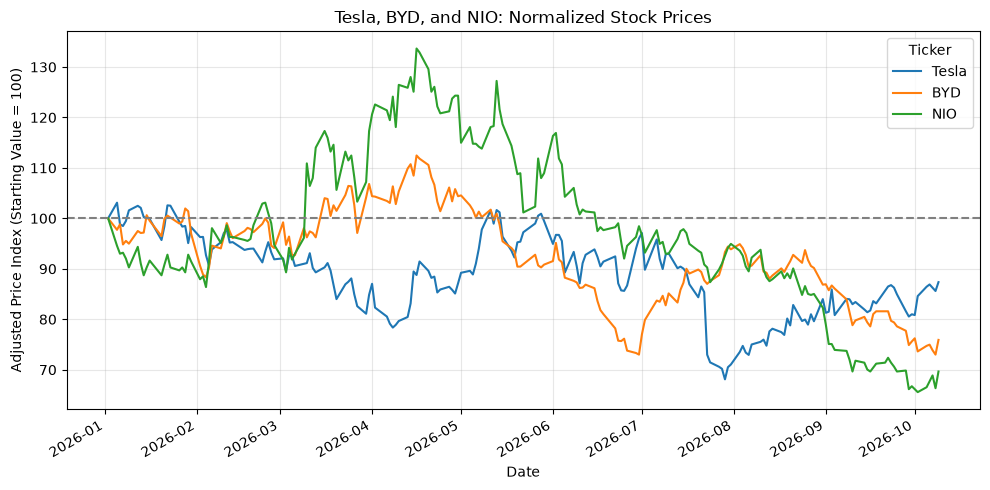

Price change over the study period (%):
Ticker
TSLA    -12.64
BYDDY   -24.09
NIO     -30.35
dtype: float64


In [10]:
normalized = prices / prices.iloc[0] * 100
ax = normalized.rename(columns={
    "TSLA": "Tesla",
    "BYDDY": "BYD",
    "NIO": "NIO"
}).plot(figsize=(10, 5))
ax.axhline(100, color="gray", linestyle="--")
ax.set_title("Tesla, BYD, and NIO: Normalized Stock Prices")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted Price Index (Starting Value = 100)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
period_returns = (prices.iloc[-1] / prices.iloc[0] - 1) * 100
print("Price change over the study period (%):")
print(period_returns.round(2))

**Figure caption:** Adjusted closing prices for Tesla, BYD, and
NIO, normalized to 100 on the common starting date. This allows
comparison of relative performance despite different share price
levels. An index of 110 represents a 10% increase from the start,
while 90 represents a 10% decrease.

### Relative Stock Performance

From January 2 to October 9, 2026, all three stocks declined.
Tesla fell 12.64%, BYD fell 24.09%, and NIO fell 30.35%.

Tesla had the smallest decline, outperforming BYD by 11.45
percentage points and NIO by 17.71 percentage points.

NIO rose strongly earlier in the period but ended with the
largest overall decline. This shows that strong performance
during part of the period did not necessarily lead to a
positive result over the full study window.

In [ ]:
returns = prices.pct_change(fill_method=None) * 100
return_stats = returns.agg(
    ["count", "mean", "median", "min", "max", "std"]
)
print("Daily Return Statistics (%)")
display(return_stats.round(2))

Daily Return Statistics (%)


Ticker,TSLA,BYDDY,NIO
count,193.00,193.00,193.00
mean,-0.03,-0.11,-0.14
median,0.04,-0.40,-0.38
min,-14.52,-6.55,-7.81
max,8.46,8.06,15.38
std,2.86,2.38,3.24


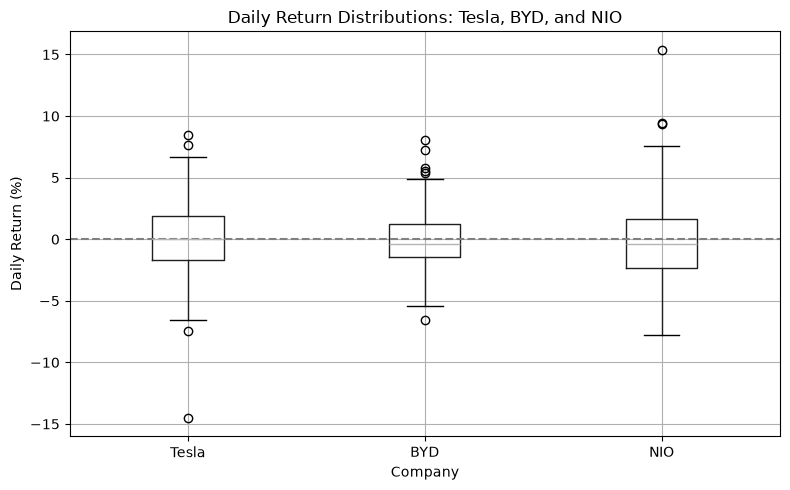

In [ ]:
plot_returns = returns.rename(columns={
    "TSLA": "Tesla",
    "BYDDY": "BYD",
    "NIO": "NIO"
})
fig, ax = plt.subplots(figsize=(8, 5))
plot_returns.boxplot(ax=ax)
ax.axhline(0, color="gray", linestyle="--")
ax.set_title("Daily Return Distributions: Tesla, BYD, and NIO")
ax.set_xlabel("Company")
ax.set_ylabel("Daily Return (%)")
plt.tight_layout()
plt.show()

**Figure caption:** Daily return distributions for Tesla, BYD,
and NIO over the same study period. Boxes show the middle 50%
of returns, and the line inside each box marks the median.
Points beyond the whiskers represent unusually large movements
under the boxplot rule and are retained in the analysis.

NIO had the highest daily return standard deviation at 3.24
percentage points, followed by Tesla at 2.86 and BYD at 2.38.
Tesla had the largest negative daily return (-14.52%), while
NIO had the largest positive daily return (15.38%).

Number of shared return observations: 193


Ticker,Tesla,BYD,NIO
Ticker,,,
Tesla,1.000,0.163,0.237
BYD,0.163,1.000,0.419
NIO,0.237,0.419,1.000


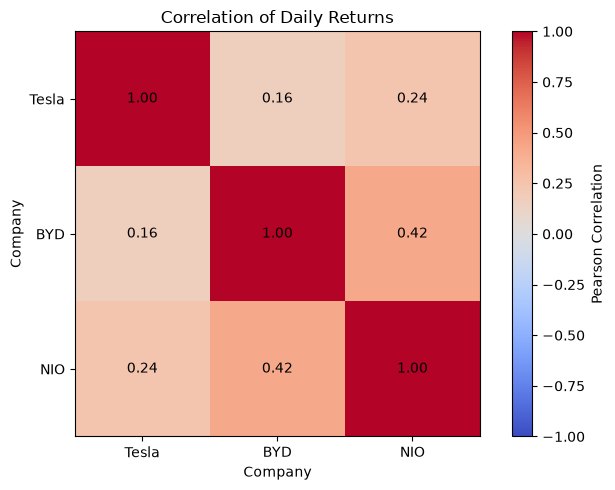

In [8]:
# Keep dates with valid returns for all three stocks
aligned_returns = plot_returns.dropna()
correlation = aligned_returns.corr(method="pearson")
print("Number of shared return observations:", len(aligned_returns))
display(correlation.round(3))
fig, ax = plt.subplots(figsize=(7, 5))
heatmap = ax.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
names = correlation.columns.tolist()
ax.set_xticks(range(len(names)), labels=names)
ax.set_yticks(range(len(names)), labels=names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )
ax.set_title("Correlation of Daily Returns")
ax.set_xlabel("Company")
ax.set_ylabel("Company")
fig.colorbar(heatmap, ax=ax, label="Pearson Correlation")
plt.tight_layout()
plt.show()

**Figure caption:** Pearson correlations between the daily
percentage returns of Tesla, BYD, and NIO, calculated using
dates with valid returns for all three stocks. The color scale
runs from -1 to 1. Diagonal values equal 1 because each stock
is perfectly correlated with itself.

### Correlation Analysis

BYD and NIO had the highest daily return correlation, approximately
0.42. This indicates a moderate positive linear relationship:
their daily returns tended to move together, although the
relationship was far from perfect.

Tesla had weaker positive correlations with BYD (approximately
0.16) and NIO (approximately 0.24). Its daily returns were
therefore less closely related to those of the other two stocks
during this period.

Although all three companies compete in the electric vehicle
industry, their daily stock movements were not strongly aligned.
These correlations do not explain the causes of co-movement
and do not prove that one stock's movement caused another's.
Results may also differ over other time periods.